# Fitting an APOGEE M-dwarf spectrum with Payne Zero

This notebook measures the metallicity and eight element abundances of one M dwarf from its APOGEE H-band spectrum. Every model spectrum is computed by Payne Zero: its equation of state, molecular equilibrium, opacities and radiative transfer, evaluated on a model atmosphere.

The atmosphere is the part that needs care. Payne Zero's label initializers stop at 4,000 K, and its atmosphere solver converges for only a few M dwarfs (the companion notebook `mdwarf_atmosphere_from_first_principles.ipynb` shows why). This notebook therefore takes the temperature structure from the MARCS grid and lets Payne Zero rebuild everything else on it. In the H band this route agrees with converged Payne Zero atmospheres to ≤ 0.003 RMS in normalized flux wherever both exist (3,300–4,000 K).

The fit has two stages:

1. **Labels.** $T_\mathrm{eff}$ and $\log g$ come from photometry and the parallax. The full spectrum then gives [M/H], a residual radial velocity and a broadening.
2. **Abundances.** With the atmosphere fixed, each element's [X/H] is fitted on the pixels that respond to that element.

The notebook runs in about 20 minutes on a laptop CPU and needs about 5 GB of memory. Run it from the repository root or from `examples/`.

In [1]:
import os

os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")

from pathlib import Path
import time

from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
import torch

from fitter import FitConfiguration, NormalizedSpectrum, fit_normalized_spectrum
from fitter.apogee.spectral_nuisance import APOGEESpectralNuisance
from payne_zero_atmosphere import (
    HELIUM_NUMBER_FRACTION,
    compute_hydrogen_fraction,
    compute_metal_log_number_abundances,
)
from payne_zero_synthesis import build_structured_atmosphere, synthesize

REPO = Path.cwd().resolve()
if not (REPO / "examples").is_dir():
    REPO = REPO.parent
DATA = REPO / "examples" / "data"
SPECTRUM_PATH = DATA / "mwmStar-0.6.0-116345665.fits"
STRUCTURE_PATH = DATA / "mdwarf_marcs_structures_v1.npz"

ORANGE, BLUE, INK, MUTED = "#d95f02", "#1f5fa8", "#1a1a1a", "#7a7a7a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": True, "axes.spines.right": True,
                     "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True})

## 1. The spectrum

The star is 2M04584599+5056378 (Gaia DR3 259731623173675904), a bright, nearby early-M dwarf at 21 pc. The file is its SDSS DR20 `mwmStar` coadd: five APOGEE visits from the APO 2.5 m telescope, already shifted to the rest frame.

The coadd stores flux, inverse variance and a pseudo-continuum fitted by the survey pipeline, on 8,575 vacuum-wavelength pixels. Dividing by that pseudo-continuum gives a normalized spectrum; the fit later multiplies the model by a low-order polynomial per detector, so the pipeline continuum does not have to be exact. Pixels flagged as bad, saturated, hit by a cosmic ray or on a sky line are masked.

2M04584599+5056378: S/N 440, 7610 of 8575 pixels usable


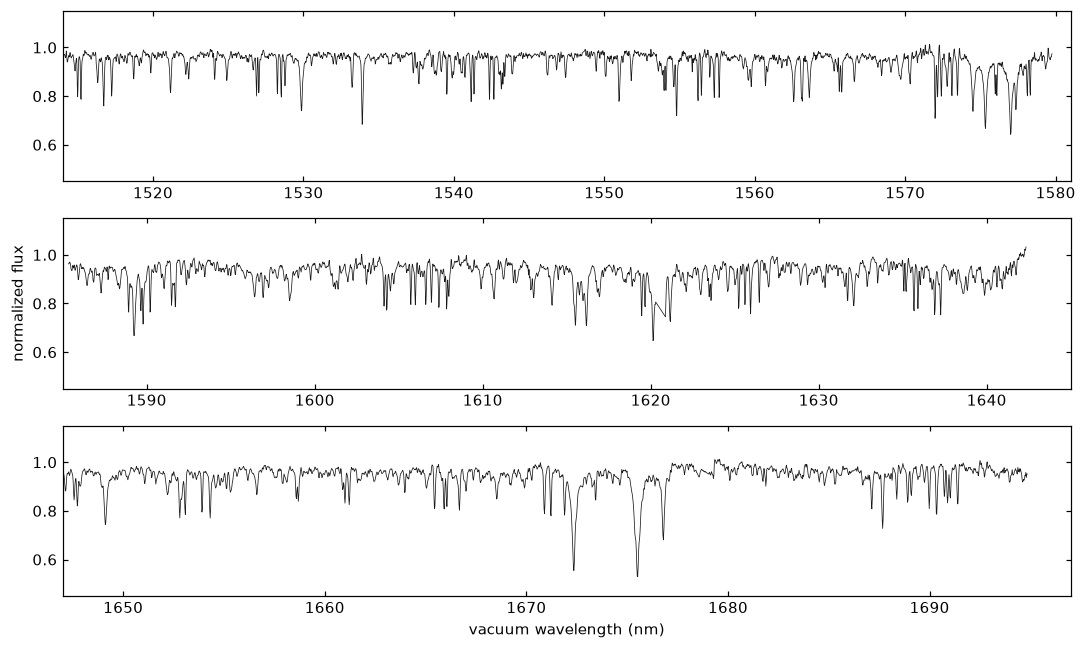

In [2]:
# APOGEE pixel-mask bits: bad pixel, cosmic ray, saturated, unfixable, bad dark,
# bad flat, bad error, no sky, significant sky line.
BAD_PIXEL_BITS = sum(1 << bit for bit in (0, 1, 2, 3, 4, 5, 6, 7, 12))


def read_mwmstar(path):
    with fits.open(path) as hdus:
        header = dict(hdus[0].header)
        hdu = hdus[3] if hdus[3].data.size else hdus[4]  # APOGEE/APO, else APOGEE/LCO
        row = hdu.data[0]
        continuum = np.asarray(row["continuum"], float)
        with np.errstate(divide="ignore", invalid="ignore"):
            flux = np.asarray(row["flux"], float) / continuum
            ivar = np.asarray(row["ivar"], float) * continuum**2
        flags = np.asarray(row["pixel_flags"]).astype(np.int64)
        snr = float(row["snr"])
    good = np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0) & ((flags & BAD_PIXEL_BITS) == 0)
    return dict(header=header, wavelength_nm=np.asarray(row["wavelength"], float) / 10.0,
                flux=np.where(good, flux, 1.0), ivar=np.where(good, ivar, 0.0), good=good, snr=snr)


star = read_mwmstar(SPECTRUM_PATH)
print(f"{star['header']['APOGEEID']}: S/N {star['snr']:.0f}, {star['good'].sum()} of {star['good'].size} pixels usable")

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharey=True)
for ax, (lo, hi) in zip(axes, [(1514, 1581), (1585, 1645), (1647, 1697)]):
    sel = star["good"] & (star["wavelength_nm"] > lo) & (star["wavelength_nm"] < hi)
    ax.plot(star["wavelength_nm"][sel], star["flux"][sel], color=INK, lw=0.5)
    ax.set_xlim(lo, hi)
axes[1].set_ylabel("normalized flux")
axes[-1].set_xlabel("vacuum wavelength (nm)")
axes[0].set_ylim(0.45, 1.15)
fig.tight_layout()

## 2. The forward model

A model spectrum is built in four steps.

**Atmosphere.** `mdwarf_marcs_structures_v1.npz` holds 252 atmospheres: every MARCS node with $T_\mathrm{eff}$ = 3,000–4,000 K, $\log g$ = 4.5–5.5 and [M/H] = −1 to +0.5 ([α/M] = 0, ξ = 1 km s⁻¹). Each is the MARCS temperature–column-mass relation $T(m)$ on Payne Zero's 80-layer depth grid; Payne Zero rebuilt the gas pressure from hydrostatic equilibrium and the electron density from its own equation of state. Between nodes, the logarithm of each column is interpolated linearly, layer by layer.

**Abundances.** Payne Zero takes a vector of 99 number fractions on the solar scale of Asplund et al. (2009). [M/H] scales all metals; an individual [X/H] overrides one element.

**Synthesis.** `build_structured_atmosphere` solves the equation of state and molecular equilibrium on the structure, and `synthesize` computes the emergent spectrum from 1,514 to 1,700 nm at $R$ = 120,000.

**Instrument.** `APOGEESpectralNuisance` applies a Gaussian broadening (one σ for rotation and macroturbulence together), a residual radial velocity and the wavelength-dependent APOGEE DR14 line-spread function, and returns the 7,514 retained APOGEE pixels.

Changing an abundance at a fixed structure ignores the atmosphere's response to that change. For [X/H] within a few tenths of [M/H] this is the usual approximation; for large changes in C or O it is not exact, because they set the molecular equilibrium.

In [3]:
structures = np.load(STRUCTURE_PATH)
GRID_AXES = (structures["metallicity"], structures["log_surface_gravity"], structures["effective_temperature"])
COLUMNS = ("temperature", "column_mass", "gas_pressure", "electron_density")
interpolators = {name: RegularGridInterpolator(GRID_AXES, np.log(structures[name])) for name in COLUMNS}


def structure_at(teff, logg, metallicity):
    point = [[metallicity, logg, teff]]
    return {name: np.exp(interpolators[name](point)[0]) for name in COLUMNS}


def abundance_vector(metallicity, x_over_h=None):
    # Linear number fractions for Z = 1-99; x_over_h maps atomic number to [X/H].
    vector = np.empty(99)
    vector[0] = compute_hydrogen_fraction(metallicity, 0.0, x_over_h)
    vector[1] = HELIUM_NUMBER_FRACTION
    vector[2:] = 10.0 ** compute_metal_log_number_abundances(metallicity, 0.0, x_over_h)
    return vector


SYNTHESIS = dict(wavelength_start_nm=1514.0, wavelength_end_nm=1700.0, resolution=120_000,
                 device="cpu", dtype="float64")


def native_spectrum(teff, logg, metallicity, x_over_h=None):
    atmosphere = build_structured_atmosphere(
        **structure_at(teff, logg, metallicity),
        elemental_abundances=abundance_vector(metallicity, x_over_h),
        microturbulence=1.0e5,  # 1 km/s, as in the MARCS grid
        device="cpu",
    )
    return synthesize(atmosphere, **SYNTHESIS)


start = time.perf_counter()
reference = native_spectrum(3800.0, 4.7, 0.0)
print(f"one synthesis: {time.perf_counter() - start:.0f} s, {reference.wavelength_nm.size} native pixels")

one synthesis: 16 s, 13905 native pixels


In [4]:
instrument = APOGEESpectralNuisance(reference.wavelength_nm, device="cpu", dtype=torch.float64)
pixels = instrument.apstar_pixel
assert np.allclose(star["wavelength_nm"][pixels], instrument.output_wavelength_nm, atol=1e-3)

observation = NormalizedSpectrum(
    wavelength=instrument.output_wavelength_nm,
    flux=star["flux"][pixels],
    inverse_variance=star["ivar"][pixels],
    mask=star["good"][pixels],
)

# One cubic Legendre continuum per detector, profiled by linear least squares at every trial.
chips = np.split(np.arange(pixels.size), np.flatnonzero(np.diff(pixels) > 1) + 1)
CONTINUUM_ORDER = 3
continuum_basis = np.zeros((pixels.size, len(chips) * (CONTINUUM_ORDER + 1)))
for index, chip in enumerate(chips):
    columns = slice(index * (CONTINUUM_ORDER + 1), (index + 1) * (CONTINUUM_ORDER + 1))
    continuum_basis[chip, columns] = np.polynomial.legendre.legvander(np.linspace(-1, 1, chip.size), CONTINUUM_ORDER)


class MDwarfModel:
    # Observed-pixel model at fixed Teff and log g; syntheses are cached by composition.

    def __init__(self, teff, logg):
        self.teff, self.logg, self.cache = teff, logg, {}

    def observed(self, metallicity, rv_km_s, broadening_km_s, x_over_h=None):
        x_over_h = x_over_h or {}
        key = (round(float(metallicity), 6), tuple(sorted((z, round(float(v), 6)) for z, v in x_over_h.items())))
        if key not in self.cache:
            native = native_spectrum(self.teff, self.logg, float(metallicity), x_over_h)
            self.cache[key] = (torch.as_tensor(native.flux_total, dtype=torch.float64),
                               torch.as_tensor(native.flux_continuum, dtype=torch.float64))
        total, continuum = self.cache[key]
        projected = instrument.project_pair(total, continuum, residual_rv_km_s=float(rv_km_s),
                                            vmacro_km_s=float(broadening_km_s))
        return projected[2].numpy()


print(f"{observation.mask.sum()} fitted pixels on {len(chips)} detectors")

7403 fitted pixels on 3 detectors


## 3. $T_\mathrm{eff}$ and $\log g$ from photometry

In an M-dwarf H-band spectrum, a hotter, more metal-poor model and a cooler, more metal-rich one can look much alike: both change the molecular lines (OH, CO, H₂O) and the atomic lines together. Fitting $T_\mathrm{eff}$ and [M/H] jointly therefore slides along a valley, and line-list errors decide where it stops. $\log g$ is constrained only weakly. Both are better set from the star's photometry and parallax, which the `mwmStar` header carries:

- $T_\mathrm{eff}$ from Gaia $BP-RP$ and 2MASS $J-H$ (Mann et al. 2015, Table 2, the relation without [Fe/H]; scatter 49 K, to be added in quadrature to the 60 K uncertainty of the calibration sample).
- Mass from $M_{K_S}$ (Mann et al. 2019, the recommended fifth-order relation) and radius from $M_{K_S}$ (Mann et al. 2015); then $g = GM/R^2$.

The relations hold for K7–M7 dwarfs, 4.6 < $M_{K_S}$ < 9.8, and −0.6 < [Fe/H] < +0.5. The $BP-RP$ calibration predates Gaia DR3, whose magnitudes the header carries; the difference is a few hundredths of a magnitude.

In [5]:
def teff_mann2015(bp_rp, j_h):
    a, b, c, d, e, f, g = 3.172, -2.475, 1.082, -0.2231, 0.01738, 0.08776, 0.04355
    x = bp_rp
    return 3500.0 * (a + b * x + c * x**2 + d * x**3 + e * x**4 + f * j_h + g * j_h**2)


def mass_mann2019(mk):
    coefficients = (-0.642, -0.208, -8.43e-4, 7.87e-3, 1.42e-4, -2.13e-4)
    return 10.0 ** sum(a * (mk - 7.5) ** i for i, a in enumerate(coefficients))


def radius_mann2015(mk):
    return 1.9515 - 0.3520 * mk + 0.01680 * mk**2


header = star["header"]
absolute_k = header["K_MAG"] + 5.0 * np.log10(header["PLX"] / 100.0)
TEFF = teff_mann2015(header["BP_MAG"] - header["RP_MAG"], header["J_MAG"] - header["H_MAG"])
mass, radius = mass_mann2019(absolute_k), radius_mann2015(absolute_k)
LOGG = 4.438 + np.log10(mass) - 2.0 * np.log10(radius)
print(f"M_K = {absolute_k:.2f}: M = {mass:.3f} Msun, R = {radius:.3f} Rsun")
print(f"Teff = {TEFF:.0f} K, log g = {LOGG:.2f}")

M_K = 5.43: M = 0.533 Msun, R = 0.536 Rsun
Teff = 3870 K, log g = 4.71


## 4. Stage 1: [M/H], velocity and broadening

With $T_\mathrm{eff}$ and $\log g$ fixed, `fit_normalized_spectrum` fits three parameters by bounded Gauss–Newton steps with finite-difference derivatives. Each new [M/H] costs one synthesis; velocity and broadening only re-project a cached synthesis. The continuum coefficients are solved exactly at every trial.

In [6]:
model = MDwarfModel(TEFF, LOGG)
stage1_configuration = FitConfiguration(
    names=("M_H", "rv_km_s", "broadening_km_s"),
    initial=np.array([0.0, 0.0, 3.0]),
    lower=np.array([-1.0, -20.0, 0.0]),
    upper=np.array([0.5, 20.0, 15.0]),
    derivative_steps=np.array([0.03, 0.2, 0.3]),
    trust_half_width=np.array([0.2, 3.0, 3.0]),
    maximum_iterations=10,
)
start = time.perf_counter()
stage1 = fit_normalized_spectrum(observation, stage1_configuration, lambda p: model.observed(*p),
                                 continuum_basis=continuum_basis)
METALLICITY, RV, BROADENING = stage1.parameters
continuum = 1.0 + continuum_basis @ stage1.continuum_coefficients  # the fitter fits model x (1 + basis @ c)
print(f"{time.perf_counter() - start:.0f} s, {len(model.cache)} syntheses, stop: {stage1.stop_reason}")
print(f"[M/H] = {METALLICITY:+.3f}, residual RV = {RV:+.2f} km/s, broadening sigma = {BROADENING:.2f} km/s")
print(f"chi2 per pixel = {stage1.mean_weighted_squared_residual:.1f}")

166 s, 18 syntheses, stop: scaled_step
[M/H] = -0.409, residual RV = +0.18 km/s, broadening sigma = 3.88 km/s
chi2 per pixel = 88.5


The fit is shown below in three windows. The χ² per pixel is far above 1: at S/N ≈ 440 the noise is 0.2%, while the line lists and the 1D LTE physics leave residuals of a few per cent in individual lines. That systematic floor, not the photon noise, sets the accuracy of everything that follows.

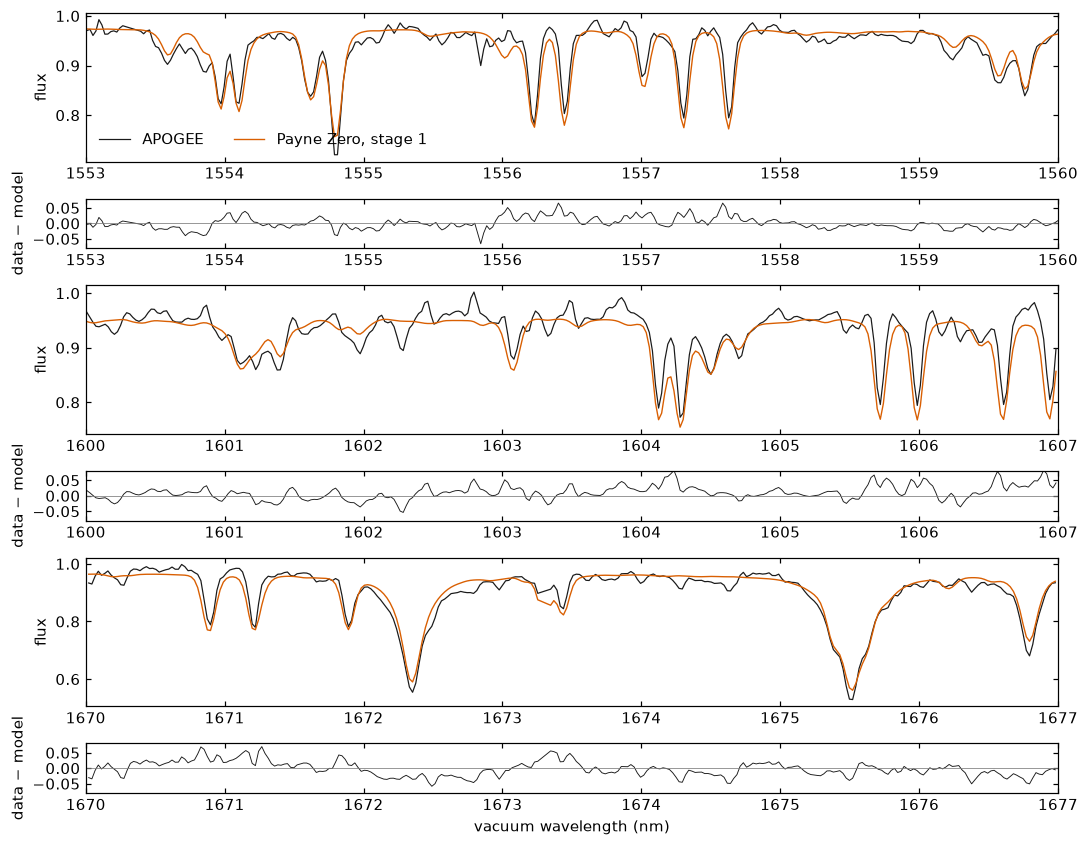

In [7]:
def plot_windows(model_flux, windows, label, extra=None):
    fig, axes = plt.subplots(2 * len(windows), 1, figsize=(10, 2.6 * len(windows)),
                             gridspec_kw={"height_ratios": [3, 1] * len(windows)})
    wave, flux, mask = observation.wavelength, observation.flux, observation.mask
    for k, (lo, hi) in enumerate(windows):
        top, bottom = axes[2 * k], axes[2 * k + 1]
        sel = mask & (wave > lo) & (wave < hi)
        top.plot(wave[sel], flux[sel], color=INK, lw=0.8, label="APOGEE")
        top.plot(wave[sel], model_flux[sel], color=ORANGE, lw=0.9, label=label)
        bottom.plot(wave[sel], flux[sel] - model_flux[sel], color=INK, lw=0.6)
        bottom.axhline(0.0, color=MUTED, lw=0.5)
        if extra is not None:
            top.plot(wave[sel], extra[1][sel], color=BLUE, lw=0.8, ls="--", label=extra[0])
        for ax in (top, bottom):
            ax.set_xlim(lo, hi)
        bottom.set_ylim(-0.08, 0.08)
        top.set_ylabel("flux")
        bottom.set_ylabel("data − model")
    axes[0].legend(loc="lower left", frameon=False, ncol=3)
    axes[-1].set_xlabel("vacuum wavelength (nm)")
    fig.tight_layout()


WINDOWS = [(1553.0, 1560.0), (1600.0, 1607.0), (1670.0, 1677.0)]
plot_windows(stage1.model_flux, WINDOWS, "Payne Zero, stage 1")

**The $T_\mathrm{eff}$–[M/H] valley.** Keeping velocity and broadening at their fitted values, the χ² of the whole spectrum can be mapped on a coarse grid of $T_\mathrm{eff}$ and [M/H] (the continuum is re-solved at every point). This takes 16 syntheses, about four minutes.

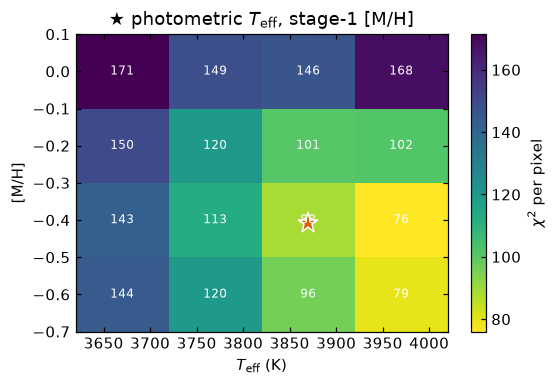

In [8]:
def chi2_per_pixel(model_flux, mask=None):
    mask = observation.mask if mask is None else mask
    weight = np.where(mask, observation.inverse_variance, 0.0)
    design = continuum_basis * model_flux[:, None]
    root = np.sqrt(weight)
    coefficients = np.linalg.lstsq(design * root[:, None], observation.flux * root, rcond=None)[0]
    return float(np.sum(weight * (observation.flux - design @ coefficients) ** 2) / mask.sum())


teff_grid = np.array([3670.0, 3770.0, 3870.0, 3970.0])
metallicity_grid = np.array([-0.6, -0.4, -0.2, 0.0])
chi2_map = np.array([[chi2_per_pixel(MDwarfModel(teff, LOGG).observed(mh, RV, BROADENING)) for teff in teff_grid]
                     for mh in metallicity_grid])

fig, ax = plt.subplots(figsize=(5.2, 3.6))
image = ax.pcolormesh(teff_grid, metallicity_grid, chi2_map, shading="nearest", cmap="viridis_r")
for row, mh in enumerate(metallicity_grid):
    for column, teff in enumerate(teff_grid):
        ax.text(teff, mh, f"{chi2_map[row, column]:.0f}", ha="center", va="center", fontsize=8, color="white")
ax.plot(TEFF, METALLICITY, "*", ms=14, color=ORANGE, mec="white")
ax.set(xlabel=r"$T_\mathrm{eff}$ (K)", ylabel="[M/H]", title="★ photometric $T_\\mathrm{eff}$, stage-1 [M/H]")
fig.colorbar(image, label=r"$\chi^2$ per pixel")
fig.tight_layout()

At solar [M/H] the χ² minimum lies near the photometric 3,870 K. At lower [M/H] it moves to the hot edge of the grid, and the lowest value on the map is at 3,970 K and [M/H] = −0.4. Left free, the spectrum would slide toward hotter, more metal-poor models, which reflects the line lists, above all the molecular ones, more than the star. Adopting the photometric $T_\mathrm{eff}$ fixes the point on the valley. The [M/H] found there still carries the line-list systematics, which the binary calibration of Section 6 is designed to remove.

## 5. Stage 2: element abundances

The atmosphere, velocity, broadening and continuum now stay fixed. For each element:

1. Raise its [X/H] by 0.2 dex and record which pixels change by more than 1% in normalized flux. These are the element's pixels.
2. Fit [X/H] on those pixels only, with the stage-1 continuum held fixed. The selected pixels are mostly line pixels, so a free continuum there would trade off against the line strength.

Carbon and oxygen come first. In an M dwarf almost all carbon sits in CO, which also binds about half the oxygen, so OH, H₂O and CO lines respond to both. The two are so strongly coupled that a joint two-parameter step is poorly conditioned; fitting them alternately (O, then C, then O again) converges reliably. The metals are then fitted one at a time with the new C and O.

Each fit costs four to six syntheses, about a minute.

In [9]:
ATOMIC_NUMBER = {"C": 6, "O": 8, "Mg": 12, "Si": 14, "K": 19, "Ca": 20, "Ti": 22, "Fe": 26}
RESPONSE_DEX, RESPONSE_THRESHOLD = 0.2, 0.01
x_over_h = {}  # atomic number -> [X/H]; elements not listed follow [M/H]
element_pixels = {}


def fit_elements(names):
    numbers = [ATOMIC_NUMBER[name] for name in names]
    current = model.observed(METALLICITY, RV, BROADENING, x_over_h)
    sensitive = np.zeros(current.size, bool)
    for z in numbers:
        raised = {**x_over_h, z: x_over_h.get(z, METALLICITY) + RESPONSE_DEX}
        sensitive |= np.abs(model.observed(METALLICITY, RV, BROADENING, raised) - current) > RESPONSE_THRESHOLD
    mask = observation.mask & sensitive
    subset = NormalizedSpectrum(wavelength=observation.wavelength, flux=observation.flux,
                                inverse_variance=observation.inverse_variance, mask=mask)
    initial = np.array([x_over_h.get(z, METALLICITY) for z in numbers])
    configuration = FitConfiguration(
        names=tuple(names), initial=initial,
        lower=np.full(len(names), -1.5), upper=np.full(len(names), 1.0),
        derivative_steps=np.full(len(names), 0.03), trust_half_width=np.full(len(names), 0.3),
        maximum_iterations=6,
    )
    result = fit_normalized_spectrum(
        subset, configuration,
        lambda p: continuum * model.observed(METALLICITY, RV, BROADENING, {**x_over_h, **dict(zip(numbers, p))}),
    )
    x_over_h.update(dict(zip(numbers, result.parameters)))
    for name in names:
        element_pixels[name] = mask
    return result


start = time.perf_counter()
for group in (["O"], ["C"], ["O"], ["Fe"], ["Mg"], ["Si"], ["K"], ["Ca"], ["Ti"]):
    result = fit_elements(group)
    values = ", ".join(f"[{n}/H] = {x_over_h[ATOMIC_NUMBER[n]]:+.3f}" for n in group)
    print(f"{values:34s} {element_pixels[group[0]].sum():5d} pixels  ({time.perf_counter() - start:4.0f} s)")

[O/H] = -0.493                      1389 pixels  (  83 s)


[C/H] = -0.405                      4975 pixels  ( 207 s)


[O/H] = -0.491                      1332 pixels  ( 264 s)


[Fe/H] = -0.318                      721 pixels  ( 329 s)


[Mg/H] = -0.293                      133 pixels  ( 439 s)


[Si/H] = -0.269                       70 pixels  ( 518 s)


[K/H] = -0.191                        18 pixels  ( 600 s)


[Ca/H] = -0.296                       80 pixels  ( 681 s)


[Ti/H] = -0.326                       73 pixels  ( 762 s)


The table compares the result with ASPCAP in SDSS DR20 (astra 0.6.0, the same coadd). ASPCAP uses MARCS atmospheres too, but a different synthesis code, line lists, continuum treatment and $T_\mathrm{eff}$ scale: it finds $T_\mathrm{eff}$ = 3,685 K and $\log g$ = 4.64 for this star, against the photometric 3,870 K and 4.71 used here. Here the metals agree with ASPCAP to within 0.15 dex, while C and O come out 0.24 dex lower; the full-spectrum [M/H] is pulled down by the molecular lines. Offsets of this size are what such systematics produce, and they are what the calibration in Section 6 is for.

        Payne Zero  ASPCAP DR20  pixels
[M/H]        -0.41        -0.19    7403
[C/H]        -0.41        -0.17    4975
[O/H]        -0.49        -0.25    1332
[Mg/H]       -0.29        -0.25     133
[Si/H]       -0.27        -0.29      70
[K/H]        -0.19        -0.10      18
[Ca/H]       -0.30        -0.23      80
[Ti/H]       -0.33        -0.35      73
[Fe/H]       -0.32        -0.18     721

chi2 per pixel: stage 1 88.5, with the abundances 59.4


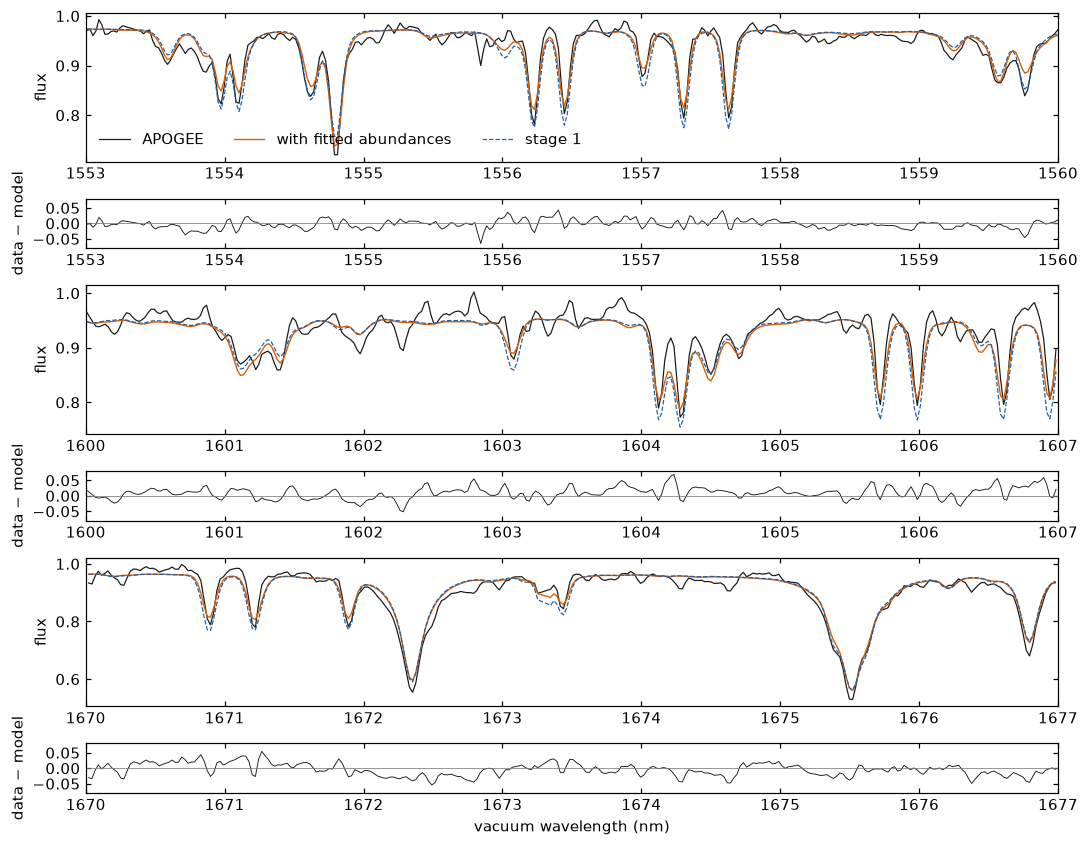

In [10]:
ASPCAP_DR20 = {"M_H": -0.19, "C": -0.17, "O": -0.25, "Mg": -0.25, "Si": -0.29, "K": -0.10, "Ca": -0.23,
               "Ti": -0.35, "Fe": -0.18}  # astraAllStarASPCAP-0.6.0, sdss_id 116345665, apo25m coadd

print(f"{'':6s}{'Payne Zero':>12s}{'ASPCAP DR20':>13s}{'pixels':>8s}")
print(f"{'[M/H]':6s}{METALLICITY:+12.2f}{ASPCAP_DR20['M_H']:+13.2f}{observation.mask.sum():8d}")
for name, z in ATOMIC_NUMBER.items():
    print(f"{'[' + name + '/H]':6s}{x_over_h[z]:+12.2f}{ASPCAP_DR20[name]:+13.2f}{element_pixels[name].sum():8d}")

final = continuum * model.observed(METALLICITY, RV, BROADENING, x_over_h)
print(f"\nchi2 per pixel: stage 1 {chi2_per_pixel(stage1.model_flux):.1f}, with the abundances {chi2_per_pixel(final):.1f}")
plot_windows(final, WINDOWS, "with fitted abundances", extra=("stage 1", stage1.model_flux))

## 6. Calibrating with FGK + M wide binaries

The two stars of a wide binary formed from the same gas, so their surface abundances should agree. (Atomic diffusion can lower the surface abundances of old stars near the main-sequence turnoff by up to about 0.1 dex; such primaries, and evolved ones, are best left out.) An FGK primary is measured with well-tested methods; the M companion is measured exactly as above. Their difference then measures the M-dwarf systematics directly:

$$\Delta_X = [X/H]_\mathrm{M} - [X/H]_\mathrm{FGK}.$$

A practical procedure:

1. Select pairs from a Gaia wide-binary catalogue (e.g. El-Badry, Rix & Heintz 2021) with a low chance-alignment probability, an FGK primary with a reliable spectroscopic analysis, and an M secondary observed by APOGEE.
2. Run Sections 1–5 on every M secondary with the same settings. Keep the line lists, structures, masks and response threshold fixed across the sample.
3. For each element, fit $\Delta_X$ as a function of the M dwarf's $T_\mathrm{eff}$; a constant plus a linear term is usually enough over 3,300–4,000 K. The scatter about the fit, minus the measurement errors, is the remaining star-to-star uncertainty.
4. Subtract the fitted $\Delta_X(T_\mathrm{eff})$ from every M-dwarf measurement, including stars outside the binary sample, but only within the $T_\mathrm{eff}$ range the pairs cover.

The function below does step 3 for one element.

In [11]:
def calibrate_offset(teff_m, delta, delta_error, pivot=3700.0):
    # Weighted linear fit delta = a + b (Teff - pivot); returns (a, b), their covariance and the extra scatter.
    design = np.column_stack([np.ones_like(teff_m), teff_m - pivot])
    weight = 1.0 / np.asarray(delta_error) ** 2
    covariance = np.linalg.inv(design.T @ (design * weight[:, None]))
    coefficients = covariance @ design.T @ (weight * delta)
    residual = delta - design @ coefficients
    extra = np.sqrt(max(0.0, np.var(residual) - np.mean(np.asarray(delta_error) ** 2)))
    return coefficients, covariance, extra

## 7. Limitations

- **The atmosphere is MARCS's, not Payne Zero's.** The temperature structure comes from MARCS; Payne Zero's own atmospheres converge only for a few M dwarfs. Against converged Payne Zero atmospheres the H-band spectra agree to ≤ 0.003 RMS at 3,300–4,000 K. Below 3,300 K there is no converged Payne Zero atmosphere to compare with.
- **Fixed structure.** Abundances are changed without recomputing the atmosphere. This is accurate for small changes but not for large changes in C/O.
- **Grid coverage.** [α/M] = 0, [C/M] = 0 and ξ = 1 km s⁻¹ only, $T_\mathrm{eff}$ 3,000–4,000 K, $\log g$ 4.5–5.5, [M/H] −1 to +0.5.
- **Line lists.** The default Payne Zero atomic and molecular lists are not calibrated on APOGEE spectra. The χ² floor and the offsets from ASPCAP mostly reflect them; the binary calibration absorbs their mean effect.
- **No formal uncertainties.** At this S/N the photon-noise errors are a few thousandths of a dex and mean little. Realistic uncertainties come from the scatter of the binary calibration and from varying $T_\mathrm{eff}$ and $\log g$ within their errors (about ±60 K and ±0.05).
- **Instrument model.** The DR14 mean line-spread function is used for every fibre.